In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import os
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Tentukan path direktori hasil EDA Anda di Google Drive
eda_dir = "/content/drive/MyDrive/color-detection/hasil_EDA_Anggota1"

# 2. Daftar file CSV yang akan kita periksa
csv_files = [
    "all_split_files.csv",
    "distribusi_split.csv",
    "test_files.csv",
    "train_files.csv",
    "validation_files.csv"
]

print("=== PEMERIKSAAN FILE CSV ===")
all_files_exist = True

for file_name in csv_files:
    full_path = os.path.join(eda_dir, file_name)
    if os.path.exists(full_path):
        print(f"[OK] File ditemukan: {file_name}")
    else:
        print(f"[ERROR] File TIDAK ditemukan: {file_name}")
        all_files_exist = False

if all_files_exist:
    print("\nSemua file CSV siap digunakan!")
else:
    print("\nAda file yang hilang. Pastikan path 'eda_dir' di atas sudah mengarah ke folder yang tepat di Google Drive Anda.")

=== PEMERIKSAAN FILE CSV ===
[OK] File ditemukan: all_split_files.csv
[OK] File ditemukan: distribusi_split.csv
[OK] File ditemukan: test_files.csv
[OK] File ditemukan: train_files.csv
[OK] File ditemukan: validation_files.csv

Semua file CSV siap digunakan!


In [13]:
# === TAHAP 2: MEMBACA DAN MENYESUAIKAN PATH HASIL CSV ===
import pandas as pd
import os

# Membaca ketiga file split dataset dari lokasi yang benar
eda_dir = "/content/drive/MyDrive/color-detection/hasil_EDA_Anggota1"
df_train = pd.read_csv(os.path.join(eda_dir, "train_files.csv"))
df_val = pd.read_csv(os.path.join(eda_dir, "validation_files.csv"))
df_test = pd.read_csv(os.path.join(eda_dir, "test_files.csv"))

# Path dasar dataset yang ada di Drive Anda
real_dataset_base = "/content/drive/MyDrive/color-detection"

def adjust_filepath(path):
    # Mengubah path bawaan '/content/dataset_baru' atau '/content/dataset' menuju lokasi aslinya di Drive
    if isinstance(path, str):
        if path.startswith("/content/dataset_baru"):
            return path.replace("/content/dataset_baru", real_dataset_base)
        elif path.startswith("/content/dataset"):
            return path.replace("/content/dataset", real_dataset_base)
    return path

# Sesuaikan path di semua dataframe
df_train['filepath'] = df_train['filepath'].apply(adjust_filepath)
df_val['filepath'] = df_val['filepath'].apply(adjust_filepath)
df_test['filepath'] = df_test['filepath'].apply(adjust_filepath)

print("=== RINGKASAN DATASET YANG TELAH DISESUAIKAN ===")
print(f"Jumlah data Train     : {len(df_train)} baris")
print(f"Jumlah data Validation: {len(df_val)} baris")
print(f"Jumlah data Test       : {len(df_test)} baris\n")

# Uji akses sampel gambar pertama yang jalurnya sudah diperbarui
sample_path = df_train['filepath'].iloc[0]
sample_label = df_train['label'].iloc[0]

print("=== UJI AKSES SAMPEL GAMBAR BARU ===")
print(f"Path baru sampel gambar pertama : {sample_path}")
print(f"Label sampel gambar pertama     : {sample_label}")

if os.path.exists(sample_path):
    print("[OK] Berhasil mengakses file gambar sampel di Drive Anda!")
else:
    print("[PERINGATAN] File gambar sampel MASIH tidak ditemukan.")
    print(f"Pastikan apakah di dalam folder '{real_dataset_base}' Anda terdapat subfolder 'dataset/blue' dsb.")

=== RINGKASAN DATASET YANG TELAH DISESUAIKAN ===
Jumlah data Train     : 3181 baris
Jumlah data Validation: 682 baris
Jumlah data Test       : 682 baris

=== UJI AKSES SAMPEL GAMBAR BARU ===
Path baru sampel gambar pertama : /content/drive/MyDrive/color-detection/dataset/blue/117023693.jpg
Label sampel gambar pertama     : blue
[OK] Berhasil mengakses file gambar sampel di Drive Anda!


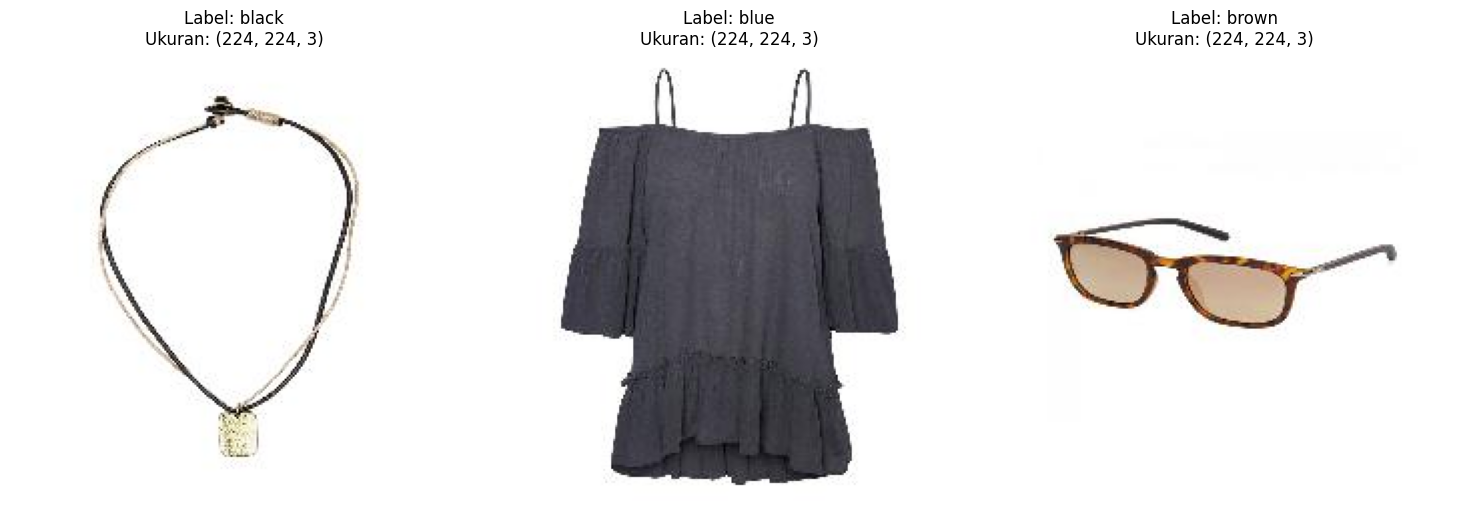

In [16]:
# === TAHAP 3: IMAGE LOADING & VISUALIZATION ===
import cv2
import numpy as np
import matplotlib.pyplot as plt

def load_image_rgb(image_path):
    """
    Membaca file gambar dan mengonversinya secara aman ke format RGB.
    """
    # Membaca gambar menggunakan OpenCV
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise ValueError(f"Gagal membaca gambar di path: {image_path}")

    # Mengonversi dari BGR (default OpenCV) ke RGB
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    return img_rgb

# Memilih beberapa sampel gambar secara acak dengan label berbeda
sample_data = df_train.groupby('label').sample(n=1, random_state=42).head(3)

# Menampilkan visualisasi sampel
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, (idx, row) in enumerate(sample_data.iterrows()):
    img_path = row['filepath']
    label = row['label']

    try:
        img = load_image_rgb(img_path)
        axes[i].imshow(img)
        axes[i].set_title(f"Label: {label}\nUkuran: {img.shape}")
        axes[i].axis('off')
    except Exception as e:
        axes[i].text(0.5, 0.5, f"Error memuat gambar\n{label}", ha='center', va='center')
        axes[i].axis('off')
        print(f"Gagal memuat {img_path}: {e}")

plt.tight_layout()
plt.show()

=== MEMULAI EKSTRAKSI FITUR MASAL ===
Catatan: Proses ini membutuhkan waktu beberapa menit karena memproses ribuan gambar.

--- Memproses Dataset TRAIN ---
[Progress] Berhasil memproses 50/3181 gambar... (22.6 detik)
[Progress] Berhasil memproses 100/3181 gambar... (45.2 detik)
[Progress] Berhasil memproses 150/3181 gambar... (66.8 detik)
[Progress] Berhasil memproses 200/3181 gambar... (89.4 detik)
[Progress] Berhasil memproses 250/3181 gambar... (111.8 detik)
[Progress] Berhasil memproses 300/3181 gambar... (134.0 detik)
[Progress] Berhasil memproses 350/3181 gambar... (157.2 detik)
[Progress] Berhasil memproses 400/3181 gambar... (180.9 detik)
[Progress] Berhasil memproses 450/3181 gambar... (204.0 detik)
[Progress] Berhasil memproses 500/3181 gambar... (227.0 detik)
[Progress] Berhasil memproses 550/3181 gambar... (249.8 detik)
[Progress] Berhasil memproses 600/3181 gambar... (272.3 detik)
[Progress] Berhasil memproses 650/3181 gambar... (295.0 detik)
[Progress] Berhasil memproses 